In [ ]:
import numpy as np
from numpy.polynomial.hermite import hermgauss
from scipy.special import hermite
import math
from matplotlib import pyplot as plt

Definition of delta function, the switch operator and constant.

In [ ]:
def d(n,m): return 0 if not n==m else 1
def p(j): return {0:0,1:1,2:3,3:2}[j]
def c(n):
  global v
  return v**(1/4) / (2**(n+3/4) * np.pi**(3/4) * math.factorial(2*n+1)**(1/2))

Definition of kinetic matrix element.

In [ ]:
def k(n,m):
  global v, cf
  if n not in [m-1,m,m+1]: return 0

  term1 = 2**(2*n) * math.factorial(2*n) * d(2*n,2*m) * (2*n+1)*(2*m+1)
  term2 = 2**(2*n) * math.factorial(2*n) * d(2*n,2*m+2) * (-(2*n+1)/2)
  term3 = 2**(2*m) * math.factorial(2*m) * d(2*n+2,2*m) * (-(2*m+1)/2)
  term4 = 2**(2*n+2) * math.factorial(2*n+2) * d(2*n+2,2*m+2) * 1/4

  return cf*c(n)*c(m)*np.sqrt(2*v)*np.sqrt(np.pi)*(2*np.pi)*(term1 + term2 + term3 + term4)

  if 2*n==2*m: return (c(2*n)*c(2*m))*(np.pi*2**(2*n)*math.factorial(2*n))*((2*n+1)*(2*m+1)+(4*v+v**2))+(c(2*n+2)*c(2*m+2))*(np.pi*2**(2*n+2)*math.factorial(2*n+2)*v**2/4)
  if 2*n==2*m+2: return (c(2*n)*c(2*m+2))*np.pi*(2*n+2)*math.factorial(2*n+2)*(-v*(2*n+1)+v**2*(2*n+1)/2)
  if 2*m==2*n+2: return (c(2*n+2)*c(2*m))*np.pi*(2*m+2)*math.factorial(2*m+2)*(-v*(2*m+1)+v**2*(2*m+1)/2)

Definition of the potential terms of the Hamiltonian $V_R(r)+ 0.5( 1+ P^σ)V_t(r)+ 0.5(1− P^σ)Vs(r)$.

In [ ]:
def VR(x): return 200*np.exp(-1.487/(2*v)*x**2)
def VT(x): return -178*np.exp(-0.639/(2*v)*x**2)
def VS(x): return -91.85*np.exp(-0.465/(2*v)*x**2)

def t1(): return k
t2 = (1,200,1.487)
t3 = (0.5,-178,0.639)
t4 = (0.5,-91.85,0.465)
t5 = (0.5,-178,0.639)
t6 = (-0.5,-91.85,0.465)

def C(n,m,x,f):
  global v
  const, v0, k0 = f
  x = x*(np.sqrt((2*v)/(2*v+k0)))
  return hermite(2*n+1)(x)*hermite(2*m+1)(x)
def CC(n,m,x,f,w):
  global v
  const, v0, k0 = f
  return c(n)*c(m)*const*(v0/(np.sqrt(2*v+k0)))*(2*np.pi) * np.sum(w*C(n,m,x,f))

def h(n,m,j,i):
  if j!=i and j!=p(i): return 0
  nPoints = int(np.ceil(((2*n+2)+(2*m+2)+1)/2))
  x,w = hermgauss(nPoints)
  term1 = k(n,m)
  term2 = CC(n,m,x,t2,w)
  term3 = CC(n,m,x,t3,w)
  term4 = CC(n,m,x,t4,w)
  term5 = CC(n,m,x,t5,w)
  term6 = CC(n,m,x,t6,w)
  return term1*d(j,i) + term2*d(j,i) + term3*d(j,i) + term4*d(j,i) + term5*d(j,p(i)) + term6*d(j,p(i))

Building the Hamiltonian matrix.

In [ ]:
def buildHm(n):
  H = np.zeros((4*n,4*n))

  for i in range(n):
    for i2 in range(n):
      for i3 in range(4):
        for i4 in range(4):
          H[i+n*(i3),i2+n*(i4)] = h(i,i2,i3,i4)

  return H

In [ ]:
def getEandW(N):
  lx = np.arange(N)+1
  e = [np.linalg.eigh(buildHm(i)) for i in lx]
  w = [i[1] for i in e]
  e = [i[0] for i in e]
  return lx, e, w

Calculation of the energy based on the number of bases and v.

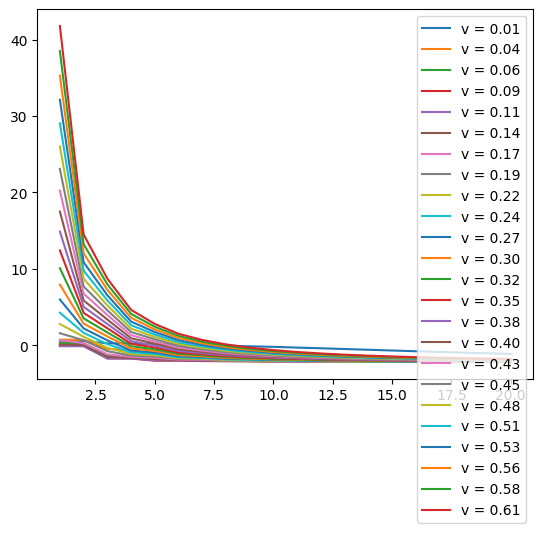

In [ ]:
vv = 1/(2*2.13**2)
cf = 41.471

N = 20

for i in np.linspace(0.01,vv+0.5,24):
  v = i
  x, e, w = getEandW(N)
  plt.plot(x,[i[0] for i in e],label="v = {:.2f}".format(v))

plt.legend()

In [2]:
#plt.plot(np.arange(1,N)*4,e,"o-",label = "v = {:.02}".format(v))
#plt.xlabel("Number of bases")
#plt.ylabel("$E_0$")
#plt.legend()
#plt.grid()
#plt.savefig("20N.png")

In [ ]:
#Hm = buildHm(N)

In [ ]:
#Ec = np.linalg.eigh(Hm)
#for i in Ec[0][:6]:
#  print(i)

In [ ]:
#cL = [i for i in Ec[1][:,3]]
#cc = []
#for i in range(4):
#  cc.append(cL[i*N:i*N+N])
#cc = [np.sum(i) for i in cc]
#print(cc)

In [ ]:
#v = 1/2.13**2/2
#cf = 41.471
#aa = 6
#H = np.zeros((aa,aa))
#H2 = np.zeros((aa,aa))
#for i in range(aa):
#  for i2 in range(aa):
#    H[i,i2] = K(i,i2)
#    H2[i,i2] = k(i,i2)

#print(H)
#print(H2)
#print(H-H2)

[[ 1.37112345e+01 -1.11951761e+01 -4.45124679e-15  1.34201895e-14
   9.82539948e-15 -4.08315032e-15]
 [-1.11951761e+01  3.19928806e+01 -2.04395017e+01 -1.15341727e-15
   1.43042770e-14  1.67083161e-14]
 [-4.45124679e-15 -2.04395017e+01  5.02745267e+01 -2.96196519e+01
  -1.69885782e-14  3.41564394e-14]
 [ 1.34201895e-14 -1.15341727e-15 -2.96196519e+01  6.85561727e+01
  -3.87812277e+01  6.46918746e-14]
 [ 9.82539948e-15  1.43042770e-14 -1.69885782e-14 -3.87812277e+01
   8.68378188e+01 -4.79348804e+01]
 [-4.08315032e-15  1.67083161e-14  3.41564394e-14  6.46918746e-14
  -4.79348804e+01  1.05119465e+02]]


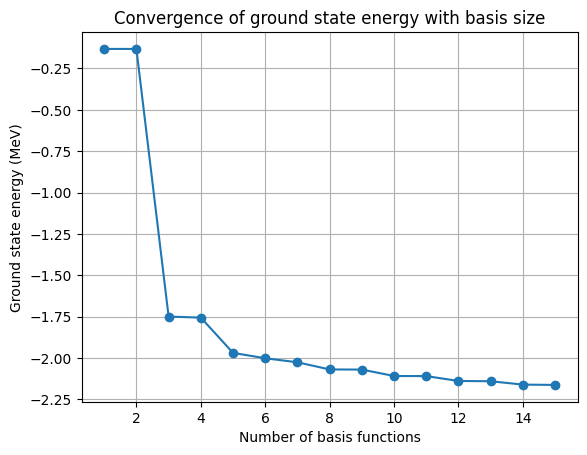

In [1]:
import numpy as np
from numpy.polynomial.hermite import hermgauss
import scipy.special as sp
from scipy.special import hermite
from scipy.linalg import eigh
from matplotlib import pyplot as plt


nu = 1 / 2.13**2/2 # in fm^-2, defined via charge radius r = 2.13 fm
conv_factor =  41.471 # MeV fm^2 , hbar^2/2m

def norm_const(n):
    return nu**(1/4) / (2**(n+3/4) * np.pi**(3/4) * sp.gamma(2*n+2)**(1/2)) # sp.gamma(2n+2) = (2n+1)!

# checking the normality factor
def R_R(n,m):
    x, w = hermgauss(2*(n+m)+2)
    f = 2*np.pi / np.sqrt(2*nu) * norm_const(n) * norm_const(m) * hermite(2*n+1)(x) * hermite(2*m+1)(x)
    integral = np.sum(w * f)
    return integral

def normality_check(M):
    matrix = np.zeros((M, M))
    for n in range(M):
        for m in range(M):
            matrix[n, m] = R_R(n, m)
    return matrix

def f_kin(n, m, x): # function in integral of kinetic term, order = 4nm + 4(n+m) + 4
    return ( (-x - 1/x)* hermite(2*n+1)(x) + 2*(2*n + 1) * hermite(2*n)(x) ) * ( (-x - 1/x)* hermite(2*m+1)(x) + 2*(2*m + 1) * hermite(2*m)(x) ) # add small value to avoid division by zero, should be fine since x starts from sigma/2 which is > 0

def K(n, m): # kinetic term
    ord = 2*(n+2) + 2*(m+2) # 2*n -1 = ord
    x, w = hermgauss(4*int(ord/2 + 1)) # number of points in quadrature, should be at least ord/2 + 1 for exact integration, decided empirically to use factor 4 bc 1/x non-poly
    integral = np.sum(w * f_kin(n, m, x))
    return conv_factor * norm_const(n) * norm_const(m) * 2*np.pi * (2*nu)**(1/2) * integral # 2pi instead of 4pi bc of integral bounds, to be checked

def single_minnesota(n, m):
    v = np.array([200, -178*0.5, -91.85*0.5]) # in MeV, to be converted, 1/2 of s and t already included
    k = np.array([1.487, 0.639, 0.465]) # in fm^-2, to be converted
    ord = 2*n + 2*m + 2 # order of H_{2n+1}*H__{2m+1} , checked to be correct
    x, w = hermgauss(int(ord/2 +1)) # test whether actually enough, should be though
    f = np.zeros_like(x)
    for i in range(len(v)):
        f += v[i] / np.sqrt(k[i] + 2*nu) * hermite(2*n+1)(np.sqrt(2*nu/(k[i]+2*nu))*x) * hermite(2*m+1)(np.sqrt(2*nu/(k[i]+2*nu))*x)
    return 2*np.pi * norm_const(n) * norm_const(m) * np.sum(w * f) # check prefactor 2*np.pi (1/2)

def single_hamiltonian(M):
    matrix = np.zeros((M, M))
    for n in range(M):
        for m in range(M):
            matrix[n, m] = K(n, m) + single_minnesota(n, m) #
    return matrix

def single_eigen(M):
    H = single_hamiltonian(M)
    eigenvalues, eigenvectors = np.linalg.eigh(H) # no overlap since basis is orthonormal
    return eigenvalues, eigenvectors

# kinetic matrix, tridiagonal
M = 6
matrix = np.zeros((M, M))
for n in range(M):
    for m in range(M):
        matrix[n, m] = K(n, m)
print(matrix)

def interaction_minnesota(n, m):
    v = 0.5*np.array([-178, 91.85]) # t & -s
    k = np.array([0.639, 0.465]) # in fm^-2, to be converted
    ord = 2*n + 2*m + 2
    x, w = hermgauss(int(ord/2 +1))
    f = np.zeros_like(x)
    for i in range(len(v)):
        f += v[i] / np.sqrt(k[i] + 2*nu) * hermite(2*n+1)(np.sqrt(2*nu/(k[i]+2*nu))*x) * hermite(2*m+1)(np.sqrt(2*nu/(k[i]+2*nu))*x)
    return 2*np.pi * norm_const(n) * norm_const(m) * np.sum(w * f)

def double_hamiltonian(M):
    matrix = np.zeros((2*M, 2*M))
    for n in range(M):
        for m in range(M):
            matrix[n, m] = K(n, m) + single_minnesota(n, m) # upper left block
            matrix[n+M, m+M] = K(n, m) + single_minnesota(n, m) # lower right block
            matrix[n, m+M] = interaction_minnesota(n, m) # upper right block
            matrix[n+M, m] = interaction_minnesota(n, m) # lower left block
    return matrix

def double_eigen(M):
    H = double_hamiltonian(M)
    eigenvalues, eigenvectors = np.linalg.eigh(H)
    return eigenvalues, eigenvectors


gs_en = []
M = 15 # number of basis functions
for m in (np.arange(M)+1):
    eigenvalues, eigenvectors = double_eigen(m)
    gs_en.append(eigenvalues[0]) # ground state energy

plt.plot((np.arange(M)+1), gs_en, marker='o')
plt.xlabel("Number of basis functions")
plt.ylabel("Ground state energy (MeV)")
plt.title("Convergence of ground state energy with basis size")
plt.grid()
plt.show()